# 06 · Proposal check on testdev: question types and repeated CV

**Purpose**: deliver two items promised in the proposal, on the 2,500 testdev questions.
- **Accuracy for relational, logical, attribute and comparative questions** (plus every other type).
- **Evaluation over multiple samplings**: cross-validation repeated 5 times with different image-to-fold assignments (5 × 5-fold), reported as mean ± SD.

**Runtime:** CPU (≈3 min). Reads the cached paths; no GPU.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
REPO_DIR = "/content/drive/MyDrive/cw-mpvr"
%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.utils import load_config, set_seed
from src.gitsync import save_and_push
cfg = load_config()
set_seed(cfg["seed"])
SEED = cfg["seed"]

Mounted at /content/drive
/content/drive/MyDrive/cw-mpvr


## 2 · Protocol code
- Writes `src/protocol.py`: repeated image-grouped CV, paired comparisons, per-type tables.
- Repeat 0 uses exactly the folds of notebook 05 (`data/cv_folds.csv`), so results stay consistent.

In [2]:
%%writefile src/protocol.py
"""Evaluation protocol helpers: repeated image-grouped cross-validation and per-type comparisons.

Written from notebooks 06/07. Repeat 0 of `image_folds` reproduces data/cv_folds.csv (notebook 05).
"""

import numpy as np
import pandas as pd
from statsmodels.stats.multitest import multipletests

from . import cwmpvr as CW
from . import evaluate as E

BETAS = [0, 0.25, 0.5, 1, 2, 4, 8]
GAMMAS = [0, 0.25, 0.5, 1, 2, 4, 8, 16]
VARIANTS = {"Answer-only (CV)": (BETAS, [0]), "Grounding-only (CV)": ([0], GAMMAS), "CW-MPVR (CV)": (BETAS, GAMMAS)}


def image_folds(image_ids, n_folds: int = 5, seed: int = 42) -> np.ndarray:
    """Assign every question to a fold so that all questions of one image share a fold."""
    imgs = np.random.default_rng(seed).permutation(sorted(set(image_ids)))
    fold_of = {im: i % n_folds for i, im in enumerate(imgs)}
    return np.array([fold_of[i] for i in image_ids])


def cross_validate(paths, gold: pd.Series, folds, betas, gammas, grounding="itm"):
    """Tune (beta, gamma) on k-1 folds, predict the held-out fold; every prediction is out-of-fold."""
    ids = gold.index
    out, chosen = [], []
    for f in np.unique(folds):
        tr, te = ids[folds != f], ids[folds == f]
        b = CW.select(CW.grid_search(paths[paths.id.isin(tr)], gold.loc[tr], betas, gammas, grounding))
        chosen.append((float(b.beta), float(b.gamma)))
        out.append(CW.cw_mpvr(paths[paths.id.isin(te)], b.beta, b.gamma, grounding))
    return pd.concat(out).reindex(ids), chosen


def repeated_cv(paths, gold: pd.Series, image_ids, repeats: int = 5, n_folds: int = 5, seed: int = 42):
    """R x k-fold CV for every tuned variant. Returns {variant: [(pred_frame, chosen), ...]}."""
    return {name: [cross_validate(paths, gold, image_folds(image_ids, n_folds, seed + r), bs, gs)
                   for r in range(repeats)]
            for name, (bs, gs) in VARIANTS.items()}


def compare(ok_a, ok_b, imgs, seed: int = 42) -> dict:
    """Paired comparison A - B: accuracy difference, image-clustered bootstrap CI, McNemar."""
    ok_a, ok_b, imgs = np.asarray(ok_a), np.asarray(ok_b), np.asarray(imgs)
    bs = E.paired_bootstrap(ok_a, ok_b, imgs, seed=seed)
    mc = E.mcnemar(ok_a, ok_b)
    return {"A − B (pts)": 100 * bs["diff"], "CI low": 100 * bs["ci_lo"], "CI high": 100 * bs["ci_hi"],
            "only A": mc["only_A"], "only B": mc["only_B"], "p McNemar": mc["p_mcnemar"], "p bootstrap": bs["p_boot"]}


def holm(df: pd.DataFrame, cols=("p McNemar", "p bootstrap")) -> pd.DataFrame:
    for c in cols:
        df[c + " (Holm)"] = multipletests(df[c], method="holm")[1]
    return df


def type_masks(meta: pd.DataFrame) -> dict:
    """Question groups promised in the proposal, plus every semantic type."""
    st, se = meta["structural"].values, meta["semantic"].values
    masks = {"all": np.ones(len(meta), bool),
             "relational (semantic: rel)": se == "rel",
             "attribute (semantic: attr)": se == "attr",
             "logical (structural)": st == "logical",
             "comparative (structural: compare)": st == "compare"}
    names = {"obj": "object", "cat": "category", "global": "global"}
    for t, name in names.items():
        if (se == t).any():
            masks[f"{name} (semantic: {t})"] = se == t
    for t in ["query", "verify", "choose"]:
        masks[f"{t} (structural)"] = st == t
    return masks


def type_table(correct: pd.DataFrame, meta: pd.DataFrame, target: str, ref: str, imgs, seed: int = 42):
    """Accuracy per question group, and target-vs-ref gain per group (Holm over groups, excluding 'all')."""
    masks = type_masks(meta)
    acc = pd.DataFrame({g: 100 * correct[m].mean() for g, m in masks.items()}).T.round(2)
    acc.insert(0, "n", [int(m.sum()) for m in masks.values()])
    gains = pd.DataFrame([{"group": g, "n": int(m.sum()),
                           **compare(correct[target].values[m], correct[ref].values[m], np.asarray(imgs)[m], seed)}
                          for g, m in masks.items()])
    rest = gains["group"] != "all"
    for c in ("p McNemar", "p bootstrap"):
        gains.loc[rest, c + " (Holm)"] = multipletests(gains.loc[rest, c], method="holm")[1]
    return acc, gains

Writing src/protocol.py


In [3]:
import importlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.paths as P, src.aggregate as A, src.evaluate as E, src.cwmpvr as CW, src.protocol as PR
for m in (P, A, E, CW, PR):
    importlib.reload(m)

VIOLET, NAVY, GREY, PALE, INK, MUTED = "#836bff", "#140f50", "#b9b8c4", "#7fc7df", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False,
})

read = lambda f: pd.read_csv(f, dtype={"id": str, "imageId": str})
meta = read("data/eval_testdev.csv").set_index("id")
GOLD = meta["answer"].map(P.normalize)
IDS, IMG = GOLD.index, meta["imageId"].values
Q, PTH = A.load_paths("results/paths_eval.jsonl.gz")
Q = Q.set_index("id")
P05 = pd.read_csv("results/05_predictions_eval.csv", dtype=str, keep_default_na=False).set_index("id").reindex(IDS)

# sanity: repeat-0 folds equal the saved notebook-05 folds
saved = meta["imageId"].map(read("data/cv_folds.csv").set_index("imageId")["fold"]).values
assert (PR.image_folds(IMG, 5, SEED) == saved).all(), "fold mismatch with data/cv_folds.csv"
print("folds consistent with notebook 05 ✓")

folds consistent with notebook 05 ✓


## 3 · Repeated cross-validation (5 × 5-fold)
- Each repeat shuffles which images go to which fold, re-tunes β, γ on 4 folds and predicts the 5th.
- Spread across repeats shows how much the result depends on the split.

In [4]:
rcv = PR.repeated_cv(PTH, GOLD, IMG, repeats=5, n_folds=5, seed=SEED)
maj_ok = (A.majority(PTH)["answer"].reindex(IDS) == GOLD).values

rows, per_rep = [], []
for name, reps in rcv.items():
    accs = [100 * (pred["answer"].values == GOLD.values).mean() for pred, _ in reps]
    for r, (pred, chosen) in enumerate(reps):
        ok = pred["answer"].values == GOLD.values
        c = PR.compare(ok, maj_ok, IMG, SEED)
        per_rep.append({"method": name, "repeat": r, "accuracy": 100 * ok.mean(),
                        "vs majority (pts)": c["A − B (pts)"], "p McNemar": c["p McNemar"], "chosen (β, γ)": chosen})
    rows.append({"method": name, "mean accuracy": np.mean(accs), "SD": np.std(accs, ddof=1),
                 "min": min(accs), "max": max(accs)})
rows.append({"method": "Majority vote", "mean accuracy": 100 * maj_ok.mean(), "SD": 0.0,
             "min": 100 * maj_ok.mean(), "max": 100 * maj_ok.mean()})
rcv_summary = pd.DataFrame(rows).set_index("method").round(2)
per_rep = pd.DataFrame(per_rep)
rcv_summary.to_csv("results/06_repeated_cv_testdev.csv")
per_rep.drop(columns="chosen (β, γ)").to_csv("results/06_repeated_cv_testdev_per_repeat.csv", index=False)
display(per_rep.round(4))
rcv_summary

,method,repeat,accuracy,vs majority (pts),p McNemar,"chosen (β, γ)"
0,Answer-only (CV),0,41.04,0.36,0.1755,"[(1.0, 0.0), (0.5, 0.0), (1.0, 0.0), (0.5, 0.0..."
1,Answer-only (CV),1,41.00,0.32,0.2430,"[(0.5, 0.0), (1.0, 0.0), (1.0, 0.0), (0.5, 0.0..."
2,Answer-only (CV),2,40.96,0.28,0.3240,"[(1.0, 0.0), (0.25, 0.0), (0.5, 0.0), (1.0, 0...."
3,Answer-only (CV),3,40.96,0.28,0.3240,"[(0.5, 0.0), (1.0, 0.0), (0.25, 0.0), (1.0, 0...."
4,Answer-only (CV),4,40.96,0.28,0.3240,"[(1.0, 0.0), (1.0, 0.0), (1.0, 0.0), (0.25, 0...."
5,Grounding-only (CV),0,40.64,-0.04,1.0000,"[(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, ..."
6,Grounding-only (CV),1,41.04,0.36,0.2221,"[(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, ..."
7,Grounding-only (CV),2,41.04,0.36,0.2221,"[(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, ..."
8,Grounding-only (CV),3,41.04,0.36,0.2221,"[(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, ..."
9,Grounding-only (CV),4,41.04,0.36,0.2221,"[(0.0, 0.25), (0.0, 0.25), (0.0, 0.25), (0.0, ..."


,mean accuracy,SD,min,max
method,,,,
Answer-only (CV),40.98,0.04,40.96,41.04
Grounding-only (CV),40.96,0.18,40.64,41.04
CW-MPVR (CV),41.02,0.29,40.72,41.32
Majority vote,40.68,0.00,40.68,40.68


## 4 · Accuracy by question type (proposal types first)
- Rows: overall, then the four promised groups (relational, attribute, logical, comparative), then the remaining types.
- CW-MPVR (CV) = repeat 0, identical to notebook 05.

In [5]:
methods = ["Greedy", "Majority vote", "Answer-only", "CW-MPVR (CV)", "LXMERT"]
CORRECT = pd.DataFrame({m: (P05[m].values == GOLD.values) for m in methods}, index=IDS)
acc_t, gain_t = PR.type_table(CORRECT, meta.loc[IDS], "CW-MPVR (CV)", "Majority vote", IMG, SEED)
acc_t.to_csv("results/06_accuracy_by_type_testdev.csv")
gain_t.to_csv("results/06_gain_by_type_testdev.csv", index=False)
display(acc_t)
gain_t.round(4)

,n,Greedy,Majority vote,Answer-only,CW-MPVR (CV),LXMERT
all,2500,40.20,40.68,41.12,40.96,59.20
relational (semantic: rel),1055,35.07,35.64,35.92,35.92,51.66
attribute (semantic: attr),1031,43.45,43.26,43.65,43.36,64.89
logical (structural),359,60.45,61.84,62.67,63.23,75.77
comparative (structural: compare),117,50.43,50.43,49.57,50.43,63.25
object (semantic: obj),155,61.29,61.94,63.23,63.87,87.10
category (semantic: cat),228,34.65,38.16,39.04,38.16,50.00
global (semantic: global),31,41.94,38.71,38.71,38.71,54.84
query (structural),1353,27.27,27.94,28.38,28.09,45.08
verify (structural),447,58.61,56.82,56.82,56.60,78.75


,group,n,A − B (pts),CI low,CI high,only A,only B,p McNemar,p bootstrap,p McNemar (Holm),p bootstrap (Holm)
0,all,2500,0.2800,-0.2816,0.8884,30,23,0.4101,0.3668,NaN,NaN
1,relational (semantic: rel),1055,0.2844,-0.7512,1.3170,16,13,0.7111,0.6592,1.0,1.0
2,attribute (semantic: attr),1031,0.0970,-0.5093,0.7470,7,6,1.0000,0.8976,1.0,1.0
3,logical (structural),359,1.3928,-0.2778,3.3241,7,2,0.1797,0.1424,1.0,1.0
4,comparative (structural: compare),117,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,1.0,1.0
5,object (semantic: obj),155,1.9355,-0.6536,5.0314,4,1,0.3750,0.2392,1.0,1.0
6,category (semantic: cat),228,0.0000,-2.1645,2.2222,3,3,1.0000,1.0000,1.0,1.0
7,global (semantic: global),31,0.0000,0.0000,0.0000,0,0,1.0000,1.0000,1.0,1.0
8,query (structural),1353,0.1478,-0.6325,0.9954,16,14,0.8555,0.8008,1.0,1.0
9,verify (structural),447,-0.2237,-1.5590,1.1038,4,5,1.0000,0.8752,1.0,1.0


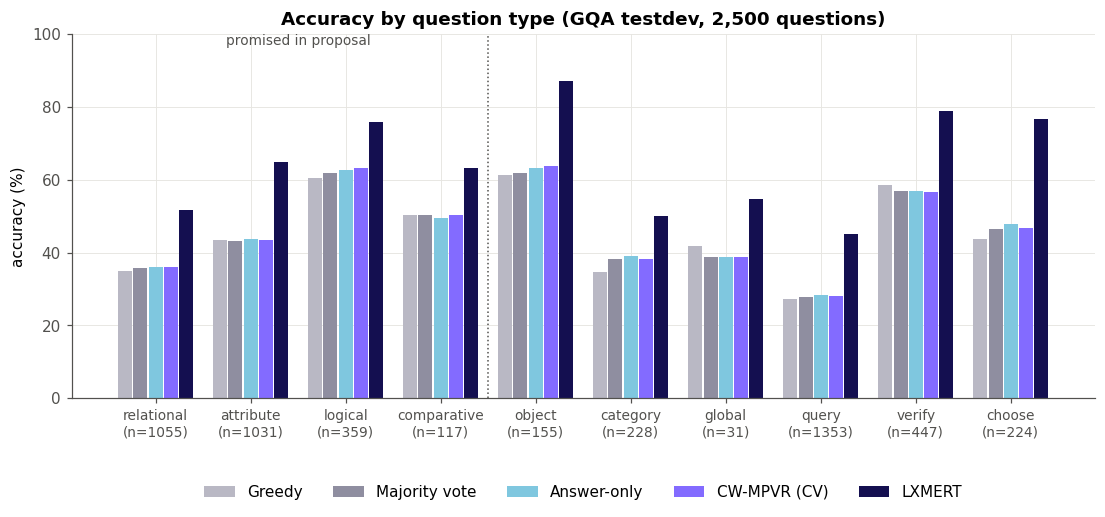

In [6]:
show = acc_t.drop(index="all")
fig, ax = plt.subplots(figsize=(12, 4.3))
x = np.arange(len(show)); w = 0.8 / len(methods)
cols = {"Greedy": GREY, "Majority vote": "#8f8ea0", "Answer-only": PALE, "CW-MPVR (CV)": VIOLET, "LXMERT": NAVY}
for i, m in enumerate(methods):
    ax.bar(x + (i - (len(methods) - 1) / 2) * w, show[m], w * 0.92, color=cols[m], label=m)
ax.set_xticks(x, [f"{g.split(' (')[0]}\n(n={n})" for g, n in zip(show.index, show.n)], fontsize=9)
ax.axvline(3.5, color=MUTED, linestyle=":", linewidth=1)
ax.text(1.5, 97, "promised in proposal", ha="center", fontsize=9, color=MUTED)
ax.set_ylim(0, 100); ax.set_ylabel("accuracy (%)")
ax.set_title("Accuracy by question type (GQA testdev, 2,500 questions)")
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.savefig("figures/06_accuracy_by_type_testdev.png"); plt.show()

## 5 · Summary (copy this output)

In [7]:
pd.set_option("display.width", 200)
print("=== Repeated CV (5 x 5-fold), testdev"); print(rcv_summary.to_string())
print("\n=== Per repeat"); print(per_rep.drop(columns="chosen (β, γ)").round(4).to_string(index=False))
print("\n=== Chosen (β, γ), CW-MPVR"); [print(r, c) for r, c in zip(per_rep[per_rep.method == "CW-MPVR (CV)"].repeat, per_rep[per_rep.method == "CW-MPVR (CV)"]["chosen (β, γ)"])]
print("\n=== Accuracy by type"); print(acc_t.to_string())
print("\n=== CW-MPVR (CV) vs majority by type"); print(gain_t.round(4).to_string(index=False))

=== Repeated CV (5 x 5-fold), testdev
                     mean accuracy    SD    min    max
method                                                
Answer-only (CV)             40.98  0.04  40.96  41.04
Grounding-only (CV)          40.96  0.18  40.64  41.04
CW-MPVR (CV)                 41.02  0.29  40.72  41.32
Majority vote                40.68  0.00  40.68  40.68

=== Per repeat
             method  repeat  accuracy  vs majority (pts)  p McNemar
   Answer-only (CV)       0     41.04               0.36     0.1755
   Answer-only (CV)       1     41.00               0.32     0.2430
   Answer-only (CV)       2     40.96               0.28     0.3240
   Answer-only (CV)       3     40.96               0.28     0.3240
   Answer-only (CV)       4     40.96               0.28     0.3240
Grounding-only (CV)       0     40.64              -0.04     1.0000
Grounding-only (CV)       1     41.04               0.36     0.2221
Grounding-only (CV)       2     41.04               0.36     0.2221
Grou

## 6 · Save to GitHub

In [ ]:
save_and_push("notebooks/06_types_repeated_cv_testdev.ipynb", "Add proposal question types and repeated 5x5 CV on testdev")